# EEG basics - Study the N170 wave
---
Link to the dataset: https://osf.io/pfde9/overview

The N170 is EEG wave elicited in a face perception task, specifically associated to the perception of a face-related visual stimulus (Rossion & Jacques, 2011; https://books.google.com/books?hl=it&lr=&id=gItoAgAAQBAJ&oi=fnd&pg=PA115&dq=N170+face+eeg&ots=B2PKDRJjSH&sig=Ri5G-RL1D4UWIcu79fD7sZfzEL4). The experiment is a modified version from Rossion & Caharel (2011), using their stimuli. In this task, an image of a face, car, scrambled face, or scrambled car was presented on each trial in the center of the screen, and participants responded whether the stimulus was an “object” (face or car) or a “texture” (scrambled face or scrambled car).

<table>
  <tr>
    <td style="text-align:center; width:25%;">
      <img src="../datasets/stimuli/back_V10.bmp" width="200"><br>
      <em>Car</em>
    </td>
    <td style="text-align:center; width:25%;">
      <img src="../datasets/stimuli/S_back_V10.bmp" width="200"><br>
      <em>Scrambled Car</em>
    </td>
    <td style="text-align:center; width:25%;">
      <img src="../datasets/stimuli/back_10.bmp" width="200"><br>
      <em>Face</em>
    </td>
    <td style="text-align:center; width:25%;">
      <img src="../datasets/stimuli/S_back_10.bmp" width="200"><br>
      <em>Scrambled Face</em>
    </td>
  </tr>
</table>




[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alanturin-g/Computational_Neuroscience_UNITO_2026/blob/main/Borriero_4_EEG_basics.ipynb)

# Import

In [ ]:
! pip install pandas openpyxl mne

In [124]:
import mne
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from scipy.signal import welch
from mne.channels import find_ch_adjacency, make_1020_channel_selections
from mne.stats import spatio_temporal_cluster_test, spatio_temporal_cluster_1samp_test, permutation_cluster_1samp_test, permutation_cluster_test
from scipy.stats import linregress
from scipy.signal import find_peaks
import seaborn as sns
from mne.time_frequency import morlet


# Download some files

In [ ]:
# A wrapper method to download files

import os, subprocess, shlex
import os
import subprocess

def download_from_drive(file_keyword, base_folder="."):
    file_name, file_ID = files_dict[file_keyword]
    DEST_PATH = os.path.join(base_folder, file_name)
    if not os.path.exists(DEST_PATH):
        URL = f"https://drive.usercontent.google.com/download?id={file_ID}&confirm=t"
        cmd = ["wget", "-q", "--show-progress", "--progress=bar:force:noscroll",
            "--no-check-certificate", "-O", DEST_PATH, URL]
        ret = subprocess.call(cmd)  # shell=False by default
        if ret != 0:
            raise RuntimeError("Download failed. Check sharing settings or FILE_ID.")
        else:
            print("Downloaded " + file_name + "!")
    else:
        print(file_name + " already present:", DEST_PATH)   

In [147]:
files_dict = {'subj_1_set':('subj_1.set','1toT_Y9ErUqdRU0W1wsT9uo3OjbrwN_lT'),
              'subj_1_fdt':('subj_1.fdt','1-R8xBXQmYVDfId57JVmvBLOKE_1Dk2kc'),
              'subj_2_set':('subj_2.set','1mA6IyPKpoVS5wyLEo03NR-68vB7NFuz_'),
              'subj_2_fdt':('subj_2.fdt','1CtrcQ6BFDkm36fBTO6zNcHzyO3syw-Y_'),
              'subj_3_set':('subj_3.set','1uLopKDvHSiraMZ3IbXdAW5-1HqdSG6tx'),
              'subj_3_fdt':('subj_3.fdt','1YIrFjPu4H1vruiA8UEEALk_rM-APzoFw'),
              'subj_4_set':('subj_4.set','1m8wezCSxZDYsjYK-Q8otIs_kn3pt1HJh'),
              'subj_4_fdt':('subj_4.fdt','1hBAzfzQBvGoc_XBpqLHFUx1cDbJjPSn6'),
              'subj_5_set':('subj_5.set','1aUwqDIec4mmYKHWXcdHDpvYa3QP7xXpm'),
              'subj_5_fdt':('subj_5.fdt','1PNaos2LzCLuDT9_fZXSZcl27T4bH4RR8'),
              }

In [ ]:
for key in files_dict.keys():
  download_from_drive(key)

# Utils

In [2]:
### Utils function to find the nearest value belonging to a list with respect to a target value
def dsearchn(x, value):
    dist_from_value = np.abs(x-value)
    return np.where(dist_from_value == dist_from_value.min())[0][0]

# Load the data - one subject

In [ ]:
subj='1'

# path='../datasets/pfde9-osfstorage-N170 All Data and Scripts-archive/'+subj+'/'
# file_name=subj+'_N170_shifted_ds_reref_ucbip_hpfilt_ica_corr_cbip_elist_bins_epoch.set'
path='../content/'
file_name='subj'+subj+'.set'

epochs = mne.io.read_epochs_eeglab(path+file_name)
data = epochs.get_data()       # NumPy array: (n_channels, n_samples)
sfreq = epochs.info["sfreq"]   # Sampling frequency, Hz
ch_names = epochs.ch_names
times = epochs.times           # Seconds
events = epochs.events

print('Data shape: ',data.shape) #(n_epochs,n_channels,n_trials)
print('Sampling frequency: ',sfreq)
# raw.plot()

Extracting parameters from c:\Unito\PostDoc\CorsoFisica_year3\notebooks\..\datasets\pfde9-osfstorage-N170 All Data and Scripts-archive\32\32_N170_shifted_ds_reref_ucbip_hpfilt_ica_corr_cbip_elist_bins_epoch.set...
Not setting metadata
299 matching events found
No baseline correction applied
0 projection items activated
Ready.
Data shape:  (299, 35, 256)
Sampling frequency:  256.0


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1686767063.py:6: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name)


### Plot the channels

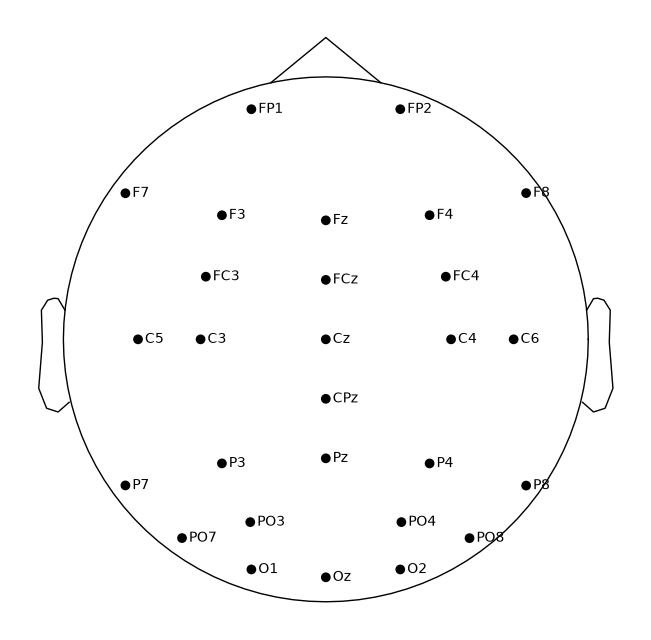

In [4]:
### Exclude some channels for the plot
exclude = [ 'HEOG_left',
            'HEOG_right',
            'VEOG_lower',
            '(corr) HEOG',
            '(corr) VEOG',
            '(uncorr) HEOG',
            '(uncorr) VEOG']  # Channels to exclude
epochs_exc_ch = epochs.copy().drop_channels(exclude)

epochs_exc_ch.plot_sensors(kind="topomap", ch_type="eeg",
                           show_names=True)
plt.show()

In [5]:
### Save the data with the excluded channels
data = epochs_exc_ch.get_data()
print('New data shape: ', data.shape)


New data shape:  (299, 28, 256)


### Plot the data

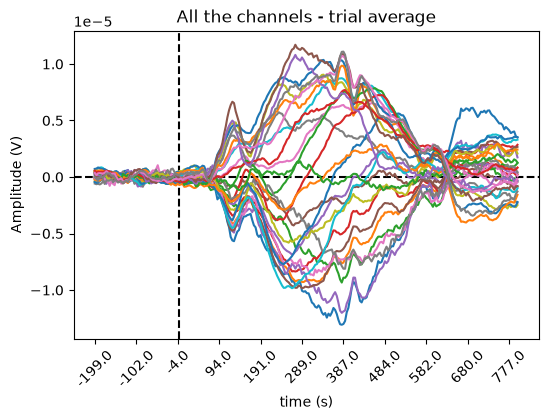

In [6]:
step = 25
fig,ax = plt.subplots(1,figsize=(6,4))
ax.axvline(0,color='black',linestyle='--')
ax.axhline(0,color='black',linestyle='--')
ax.plot(times, data[:,:,].mean(axis=0).T, )
ax.set_xticks(times[::step], labels=np.round(times[::step],3)*1000,
              rotation=45)
ax.set_xlabel('time (s)')
ax.set_ylabel('Amplitude (V)')
ax.set_title('All the channels - trial average')

plt.show()

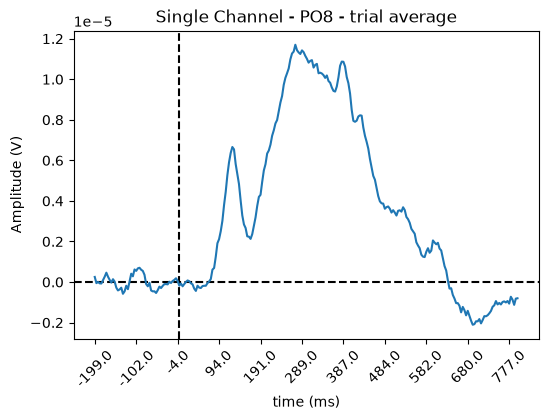

In [7]:
ch_idx = np.where(np.array(ch_names)=='PO8')[0][0]
step = 25 # To plot the x ticks
fig,ax = plt.subplots(1,figsize=(6,4))
ax.axvline(0,color='black',linestyle='--')
ax.axhline(0,color='black',linestyle='--')
ax.plot(times, data[:,ch_idx,].mean(axis=0), )
ax.set_xticks(times[::step], labels=np.round(times[::step],3)*1000,
              rotation=45)
ax.set_xlabel('time (ms)')
ax.set_ylabel('Amplitude (V)')
ax.set_title('Single Channel - '+ch_names[ch_idx]+' - trial average')

plt.show()

### Group the trials by experimental condition

In [8]:
xlsx_path = '../datasets/N170_Event_Code_Scheme.xlsx'
df = pd.read_excel(xlsx_path)
df


,Face Perception N170,Unnamed: 1
0,NaN,NaN
1,Stimulus Event Codes,NaN
2,NaN,NaN
3,Stimulus Type,Event Code
4,face,1-40
5,car,41-80
6,scrambled face,101-140
7,scrambled car,141-180
8,NaN,NaN
9,NaN,NaN


In [9]:
events = epochs.events # events id and correspondig time 
events

array([[   51,     0,     1],
       [  307,     0,     2],
       [  563,     0,     3],
       [  819,     0,     4],
       [ 1075,     0,     5],
       [ 1331,     0,     6],
       [ 1587,     0,     7],
       [ 1843,     0,     8],
       [ 2099,     0,     9],
       [ 2355,     0,    10],
       [ 2611,     0,    11],
       [ 2867,     0,    12],
       [ 3123,     0,    13],
       [ 3379,     0,    14],
       [ 3635,     0,    15],
       [ 3891,     0,    16],
       [ 4147,     0,    17],
       [ 4403,     0,    18],
       [ 4659,     0,    19],
       [ 4915,     0,    20],
       [ 5171,     0,    21],
       [ 5427,     0,    22],
       [ 5683,     0,    23],
       [ 5939,     0,    24],
       [ 6195,     0,    25],
       [ 6451,     0,    26],
       [ 6707,     0,    27],
       [ 6963,     0,    28],
       [ 7219,     0,    29],
       [ 7475,     0,    30],
       [ 7731,     0,    31],
       [ 7987,     0,    32],
       [ 8243,     0,    33],
       [ 8

In [10]:
events_id = epochs.event_id # Stimulus corresopnding to each event id
events_id

{'B2(49)/201': 1,
 'B4(148)/201': 2,
 'B4(177)/201': 3,
 'B1(26)/201': 4,
 'B4(174)/201': 5,
 'B3(132)/201': 6,
 'B3(127)/201': 7,
 'B3(109)/201': 8,
 'B2(68)/201': 9,
 'B1(40)/201': 10,
 'B3(140)/201': 11,
 'B3(104)/201': 12,
 'B4(150)/201': 13,
 'B2(41)/201': 14,
 'B4(144)/201': 15,
 'B3(128)/201': 16,
 'B4(142)/201': 17,
 'B3(111)/201': 18,
 'B1(1)/201': 19,
 'B4(175)/201': 20,
 'B3(120)/201': 21,
 'B4(152)/201': 22,
 'B4(155)/201': 23,
 'B3(125)/201': 24,
 'B2(70)/201': 25,
 'B4(180)/201': 26,
 'B2(78)/201': 27,
 'B3(126)/201': 28,
 'B3(116)/201': 29,
 'B2(47)/201': 30,
 'B2(66)/201': 31,
 'B1(3)/201': 32,
 'B3(136)/201': 33,
 'B4(176)/201': 34,
 'B1(25)/201': 35,
 'B3(101)/201': 36,
 'B4(157)/201': 37,
 'B2(46)/201': 38,
 'B4(168)/201': 39,
 'B1(4)/201': 40,
 'B3(113)/201': 41,
 'B1(8)/201': 42,
 'B1(5)/201': 43,
 'B4(159)/201': 44,
 'B4(156)/201': 45,
 'B1(30)/201': 46,
 'B1(27)/201': 47,
 'B4(160)/201': 48,
 'B2(52)/201': 49,
 'B3(129)/201': 50,
 'B2(55)/201': 51,
 'B4(173)/201'

In [11]:
id_to_label = {v: k for k, v in epochs.event_id.items()}
id_to_label

{1: 'B2(49)/201',
 2: 'B4(148)/201',
 3: 'B4(177)/201',
 4: 'B1(26)/201',
 5: 'B4(174)/201',
 6: 'B3(132)/201',
 7: 'B3(127)/201',
 8: 'B3(109)/201',
 9: 'B2(68)/201',
 10: 'B1(40)/201',
 11: 'B3(140)/201',
 12: 'B3(104)/201',
 13: 'B4(150)/201',
 14: 'B2(41)/201',
 15: 'B4(144)/201',
 16: 'B3(128)/201',
 17: 'B4(142)/201',
 18: 'B3(111)/201',
 19: 'B1(1)/201',
 20: 'B4(175)/201',
 21: 'B3(120)/201',
 22: 'B4(152)/201',
 23: 'B4(155)/201',
 24: 'B3(125)/201',
 25: 'B2(70)/201',
 26: 'B4(180)/201',
 27: 'B2(78)/201',
 28: 'B3(126)/201',
 29: 'B3(116)/201',
 30: 'B2(47)/201',
 31: 'B2(66)/201',
 32: 'B1(3)/201',
 33: 'B3(136)/201',
 34: 'B4(176)/201',
 35: 'B1(25)/201',
 36: 'B3(101)/201',
 37: 'B4(157)/201',
 38: 'B2(46)/201',
 39: 'B4(168)/201',
 40: 'B1(4)/201',
 41: 'B3(113)/201',
 42: 'B1(8)/201',
 43: 'B1(5)/201',
 44: 'B4(159)/201',
 45: 'B4(156)/201',
 46: 'B1(30)/201',
 47: 'B1(27)/201',
 48: 'B4(160)/201',
 49: 'B2(52)/201',
 50: 'B3(129)/201',
 51: 'B2(55)/201',
 52: 'B4(173)/

In [12]:
cond_by_trial = [id_to_label[event][:2] for event in events[:,-1] if id_to_label[event][0]=='B']# Assign to each trial the corresponding condition
cond_by_trial

['B2',
 'B4',
 'B4',
 'B1',
 'B4',
 'B3',
 'B3',
 'B3',
 'B2',
 'B1',
 'B3',
 'B3',
 'B4',
 'B2',
 'B4',
 'B3',
 'B4',
 'B3',
 'B1',
 'B4',
 'B3',
 'B4',
 'B4',
 'B3',
 'B2',
 'B4',
 'B2',
 'B3',
 'B3',
 'B2',
 'B2',
 'B1',
 'B3',
 'B4',
 'B1',
 'B3',
 'B4',
 'B2',
 'B4',
 'B1',
 'B3',
 'B1',
 'B1',
 'B4',
 'B4',
 'B1',
 'B1',
 'B4',
 'B2',
 'B3',
 'B2',
 'B4',
 'B3',
 'B4',
 'B4',
 'B1',
 'B3',
 'B3',
 'B1',
 'B1',
 'B1',
 'B1',
 'B2',
 'B4',
 'B2',
 'B1',
 'B2',
 'B3',
 'B1',
 'B1',
 'B3',
 'B1',
 'B4',
 'B2',
 'B3',
 'B2',
 'B1',
 'B1',
 'B1',
 'B4',
 'B4',
 'B1',
 'B2',
 'B2',
 'B4',
 'B4',
 'B2',
 'B1',
 'B3',
 'B3',
 'B1',
 'B3',
 'B3',
 'B2',
 'B1',
 'B3',
 'B2',
 'B1',
 'B4',
 'B1',
 'B3',
 'B1',
 'B1',
 'B2',
 'B1',
 'B3',
 'B2',
 'B3',
 'B2',
 'B4',
 'B1',
 'B3',
 'B3',
 'B2',
 'B3',
 'B1',
 'B2',
 'B2',
 'B4',
 'B1',
 'B2',
 'B1',
 'B4',
 'B1',
 'B2',
 'B4',
 'B4',
 'B2',
 'B4',
 'B1',
 'B4',
 'B2',
 'B2',
 'B2',
 'B1',
 'B2',
 'B3',
 'B1',
 'B2',
 'B2',
 'B4',
 'B4',
 'B3',

In [13]:
condition_dict = {'B1':'face',
                  'B2':'car',
                  'B3':'scrambled face',
                  'B4':'scrambled car'}

In [14]:
np.unique(cond_by_trial)

array(['B1', 'B2', 'B3', 'B4'], dtype='<U2')

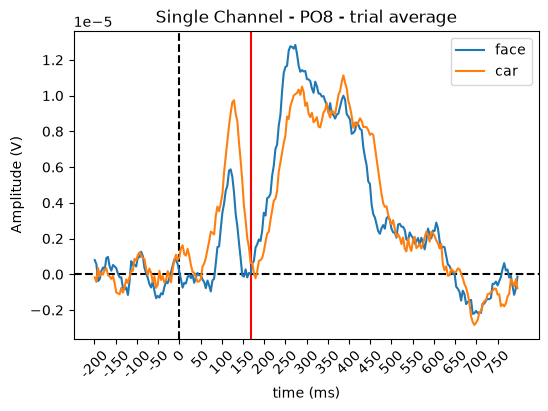

In [15]:
### Group the trials by condition and plot
conditions = ['face','car',]
ch_idx = np.where(np.array(ch_names)=='PO8')[0][0]
step = 25 # To plot the x ticks
fig,ax = plt.subplots(1,figsize=(6,4))
ax.axvline(0,color='black',linestyle='--')
ax.axvline(0.170,color='red',) # N170
ax.axhline(0,color='black',linestyle='--')
for condition in conditions:
    trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])

    ax.plot(times, data[trials_idx,ch_idx,].mean(axis=0), label=condition)
    # ax.fill_between(times,
    #                 data[trials_idx,ch_idx,].mean(axis=0) + data[trials_idx,ch_idx,].std(axis=0),
    #                 data[trials_idx,ch_idx,].mean(axis=0) - data[trials_idx,ch_idx,].std(axis=0), 
    #                 alpha=0.2)

    # ax.set_xticks(times[::step], labels=np.round(times[::step],3)*1000,
    #                 rotation=45)
    ax.set_xticks([(x-200)*0.001 for x in range(0,1000,50)],
                  labels=[str(x-200) for x in range(0,1000,50)],
                  rotation=45)
ax.set_xlabel('time (ms)')
ax.set_ylabel('Amplitude (V)')
ax.set_title('Single Channel - '+ch_names[ch_idx]+' - trial average')
plt.legend()

### Plot the activity of the four conditions over the scalp

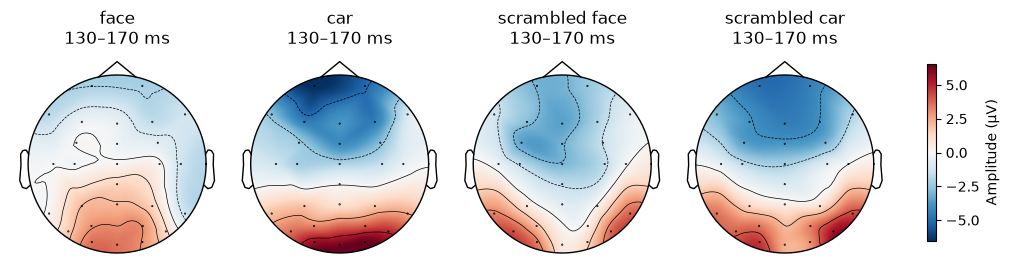

In [16]:
# Time window in seconds: 160–180 ms
tmin, tmax = 0.130, 0.170

exclude = [
    'HEOG_left',
    'HEOG_right',
    'VEOG_lower',
    '(corr) HEOG',
    '(corr) VEOG',
    '(uncorr) HEOG',
    '(uncorr) VEOG',
]

conditions = ['face', 'car', 'scrambled face', 'scrambled car']

# First calculate the values for every condition
all_values = []
all_infos = []

for condition in conditions:
    trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
    epochs_plot = epochs[trials_idx].copy().pick("eeg")

    # Drop excluded channels
    epochs_plot.drop_channels([ch for ch in exclude if ch in epochs_plot.ch_names])

    evoked = epochs_plot.average().crop(tmin=tmin, tmax=tmax)
    # Average across time and convert to µV
    values = evoked.data.mean(axis=1) * 1e6

    all_values.append(values)
    all_infos.append(evoked.info)

# Common color limits, symmetric around zero
vmax = max(np.max(np.abs(values)) for values in all_values)
if vmax == 0:
    vmax = 1.0

fig, axs = plt.subplots(1, len(conditions), figsize=(10, 4), constrained_layout=True)

for c, condition in enumerate(conditions):
    im, _ = mne.viz.plot_topomap(
        all_values[c],
        all_infos[c],
        axes=axs[c],
        cmap="RdBu_r",
        vlim=(-vmax, vmax),
        show=False,
    )

    axs[c].set_title(f"{condition:s}\n" f"{tmin * 1000:.0f}–{tmax * 1000:.0f} ms")

# One shared colorbar for all four maps
cbar = fig.colorbar(
    im,
    ax=axs.tolist(),
    orientation="vertical",
    shrink=0.45,
    fraction=0.035,
    pad=0.04,
)
cbar.set_label("Amplitude (µV)")

plt.show()

### Plot the difference of the mean of two conditions

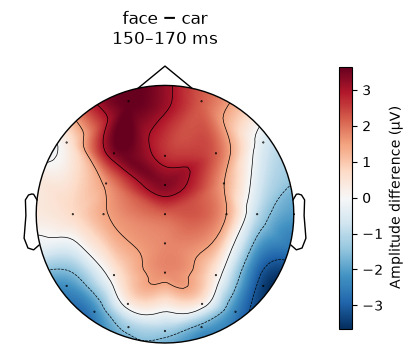

In [17]:
# Time window in seconds: 150–200 ms
tmin, tmax = 0.150, 0.170

exclude = ['HEOG_left',
           'HEOG_right',
           'VEOG_lower',
           '(corr) HEOG',
           '(corr) VEOG',
           '(uncorr) HEOG',
           '(uncorr) VEOG']

conditions = ['face', 'car']
condition_values = []

for condition in conditions:
    trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])

    epochs_plot = epochs[trials_idx].copy().pick("eeg")
    epochs_plot.drop_channels([ch for ch in exclude if ch in epochs_plot.ch_names])

    # Average across trials, then select the time window
    evoked = epochs_plot.average().crop(tmin=tmin, tmax=tmax)

    # Average across time, converted to µV
    values = evoked.data.mean(axis=1) * 1e6
    condition_values.append(values)

# Difference between conditions
difference = condition_values[0] - condition_values[1]

fig, ax = plt.subplots(figsize=(5, 4))

# Symmetric color limits around zero
vmax = np.max(np.abs(difference))
if vmax == 0:
    vmax = 1.0

im, _ = mne.viz.plot_topomap(
    difference,
    evoked.info,
    axes=ax,
    cmap="RdBu_r",
    vlim=(-vmax, vmax),
    show=False,
)

fig.colorbar(im, ax=ax, label="Amplitude difference (µV)", shrink=0.85)
ax.set_title(
    f"{conditions[0]} − {conditions[1]}\n"
    f"{tmin * 1000:.0f}–{tmax * 1000:.0f} ms"
)
plt.show()

### Time-wise t-test in the N170 window

In [18]:
epochs_exc_ch.get_data().shape

(299, 28, 256)

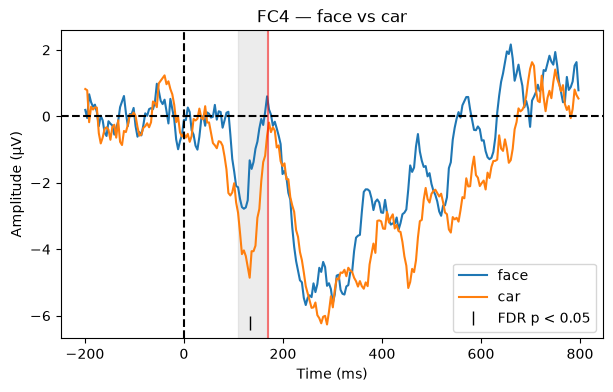

Significant point: 1


In [19]:
conditions = ["face", "car"]
ch_name = 'FC4'
ch_idx = np.where(np.array(ch_names) == ch_name)[0][0]

tmin, tmax = 0.11, 0.170
window = (times >= tmin) & (times <= tmax)

# Collect all trials belonging to each condition
condition_data = {}

for condition in conditions:
    trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
    condition_data[condition] = epochs_exc_ch.get_data()[trials_idx, ch_idx, :]

a = condition_data[conditions[0]]  # (n_Cond1_trials, n_times)
b = condition_data[conditions[1]]  # (n_Cond2_trials, n_times)

# One two-sided test per time sample within the window
t_values, p_values = ttest_ind(
    a[:, window],
    b[:, window],
    axis=0,
    equal_var=False,
)

# Correct across time samples in this window
significant, p_fdr, _, _ = multipletests(
    p_values, alpha=0.05, method="fdr_bh"
)

# Plot full ERPs
fig, ax = plt.subplots(figsize=(7, 4))

for condition in conditions:
    ax.plot(
        times * 1000,
        condition_data[condition].mean(axis=0) * 1e6,
        label=condition,
    )

ax.axvline(0, color="black", linestyle="--")
ax.axvline(170, color="red", alpha=0.5)
ax.axhline(0, color="black", linestyle="--")
ax.axvspan(tmin * 1000, tmax * 1000, color="grey", alpha=0.15)

# Mark significant samples near the bottom of the plot
ax.plot(
    times[window][significant] * 1000,
    np.full(significant.sum(), 0.05),
    "|",
    color="black",
    markersize=10,
    transform=ax.get_xaxis_transform(),
    label="FDR p < 0.05",
)

ax.set(
    xlabel="Time (ms)",
    ylabel="Amplitude (µV)",
    title=ch_name+" — "+conditions[0]+" vs "+conditions[1],
)
ax.legend()
plt.show()
print('Significant point: '+str(significant.sum()))

### Cluster permutation t-test

In [20]:
montage = epochs_exc_ch.get_montage()
info = mne.create_info(ch_names=montage.ch_names, sfreq=sfreq, ch_types='eeg')
info.set_montage(montage)
adjacency, ch = mne.channels.find_ch_adjacency(info, 'eeg')

Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28


Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=6.841285947347953e-07 max=38.74748062039442
Running initial clustering …
Using 19 thresholds from 1.00 to 37.00 for TFCE computation (h_power=2.00, e_power=0.50)
Found 7168 clusters


c:\Users\alebo\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| Permuting : 9999/9999 [00:35<00:00,  278.74it/s]


(28, 256)
[1. 1. 1. ... 1. 1. 1.]


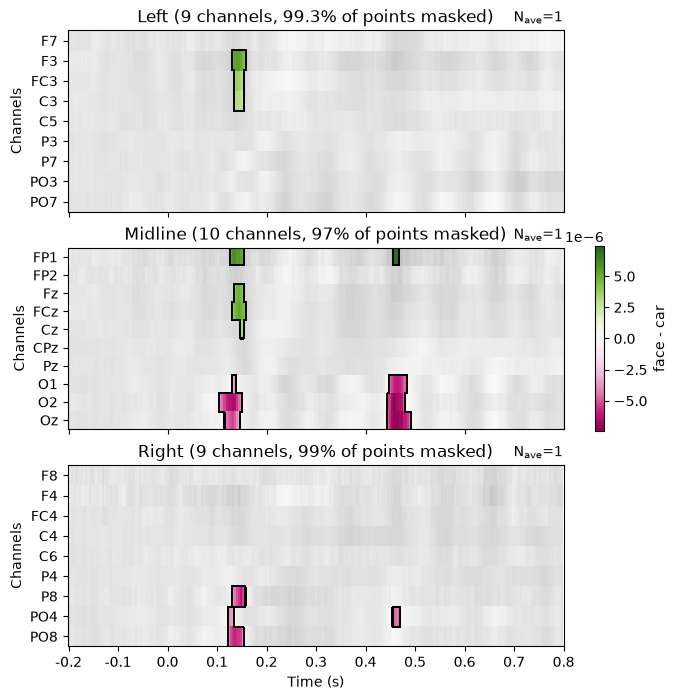

In [21]:
### CLUSTER PERMUTATION T-TEST ###
conditions = ["face", "car"]
n_permutations = 10000
pv_threshold = 0.05

montage = epochs_exc_ch.get_montage()
info = mne.create_info(ch_names=montage.ch_names, sfreq=sfreq, ch_types='eeg')
info.set_montage(montage)
adjacency, ch = mne.channels.find_ch_adjacency(info, 'eeg')
tfce = dict(start=1, step=2) # threshold free cluster enhancement - ideally start and step would be smaller 

# Collect all trials belonging to each condition
condition_data = {}

for condition in conditions:
    trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
    condition_data[condition] = data[trials_idx, :, :]

a = condition_data[conditions[0]]  # (n_Cond1_trials, n_channels, n_times)
b = condition_data[conditions[1]]  # (n_Cond2_trials, n_channels, n_times)

all_condition_trials = [a.transpose(0,2,1), b.transpose(0,2,1)]
t_obs, clusters, cluster_pv, h0 = permutation_cluster_test(all_condition_trials, 
                                                            threshold=tfce,
                                                            n_permutations=n_permutations, tail=0, 
                                                            n_jobs=-1, adjacency=adjacency)
                                                            # stat_fun=wilcoxon_stat_fun)
                                                            

# transpose clusters
clusters_=[]
for c in clusters:
    clusters_.append(c[::-1])
# Initialize a boolean mask for significant clusters (same shape as T_obs)
significant_points = np.zeros(t_obs.T.shape, dtype=bool)
# Mark cluster areas with p < 0.05 as significant
p_count=0
for cluster, p_val in zip(clusters_, cluster_pv):
    if p_val <= pv_threshold:
        significant_points[cluster] = True
        p_count +=1

print(significant_points.shape)
new_mask_diff = significant_points

# Create ROIs by checking channel labels
selections = make_1020_channel_selections(epochs_exc_ch.info, midline="12z")
time_unit = dict(time_unit="s")

# Visualize the results
diff = a.mean(axis=0) - b.mean(axis=0)
evoked_array = mne.EvokedArray(data=diff, info=info) # size: n_ch x time
fig, axes = plt.subplots(nrows=3, figsize=(8, 8))
axes = {sel: ax for sel, ax in zip(selections, axes.ravel())}
evoked_array.plot_image(
    axes=axes,
    group_by=selections,
    colorbar=False,
    show=False,
    cmap='PiYG',
    mask=new_mask_diff,
    # clim=dict(eeg=[-vmax, vmax]),
    show_names="all",
    titles=None,
    **time_unit,
    scalings = dict(eeg=1)
)
# axes['Left'].set_xticks([x/10 for x in range(11)])
# axes['Midline'].set_xticks([x/10 for x in range(11)])

axes['Right'].set_xticks([x/10 for x in range(11)])
axes['Right'].set_xticklabels([round(x/10-0.2,2) for x in range(11)])

plt.colorbar(axes["Left"].images[-1], ax=list(axes.values()), shrink=0.3, label=conditions[0]+" - "+conditions[1])
print(cluster_pv)

# Between-subjects analysis

In [ ]:
# Time window in seconds: 160–180 ms
path='../content/'


exclude = [
    'HEOG_left',
    'HEOG_right',
    'VEOG_lower',
    '(corr) HEOG',
    '(corr) VEOG',
    '(uncorr) HEOG',
    '(uncorr) VEOG',
]

conditions = ['face', 'scrambled face', 'car', 'scrambled car']

all_subj_values = []
for subj in range(1,41):# Loop over subjects    
    print(f'Subject: {subj}')
    # path='../datasets/pfde9-osfstorage-N170 All Data and Scripts-archive/'+str(subj)+'/'
    # file_name=str(subj)+'_N170_shifted_ds_reref_ucbip_hpfilt_ica_corr_cbip_elist_bins_epoch.set'
    file_name='subj'+subj+'.set'

    epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
    events = epochs.events # events id and correspondig time 
    events_id = epochs.event_id
    id_to_label = {v: k for k, v in events_id.items()}
    cond_by_trial = [id_to_label[event][:2] for event in events[:,-1] if id_to_label[event][0]=='B']# Assign to each trial the corresponding condition

    ch_names = epochs.ch_names
    times = epochs.times      

    # First calculate the values for every condition
    all_values = []
    condition_length = []
    for condition in conditions:
        trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
        # If there's an empty condition, skip the trial
        condition_length.append(len(trials_idx))
    if 0 in condition_length:
        continue
    else:
        for condition in conditions:
            trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
            epochs_plot = epochs[trials_idx].copy().pick("eeg")
            # Drop excluded channels
            epochs_plot.drop_channels([ch for ch in exclude if ch in epochs_plot.ch_names])
            evoked = epochs_plot.get_data().mean(axis=0) # Mean over trials
            # Average across time and convert to µV
            values = evoked * 1e6

            all_values.append(values)
    all_values = np.stack(all_values)
    all_subj_values.append(all_values)
all_subj_values = np.stack(all_subj_values)
print(all_subj_values.shape)


Subject: 1


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1139044653.py:21: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1139044653.py:21: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Subject: 2
Subject: 3


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1139044653.py:21: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Subject: 4


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1139044653.py:21: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


... (64 outputs left out)

Subject: 39


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1139044653.py:21: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Subject: 40
(40, 4, 28, 256)


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\1139044653.py:21: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


### Plot the the ERP of a single electrode for all the conditions - many subjects

<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\80105051.py:18: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('Amplitude ($\mu$V)');


Text(0.5, 1.0, 'Single Channel - PO8 - subject average')

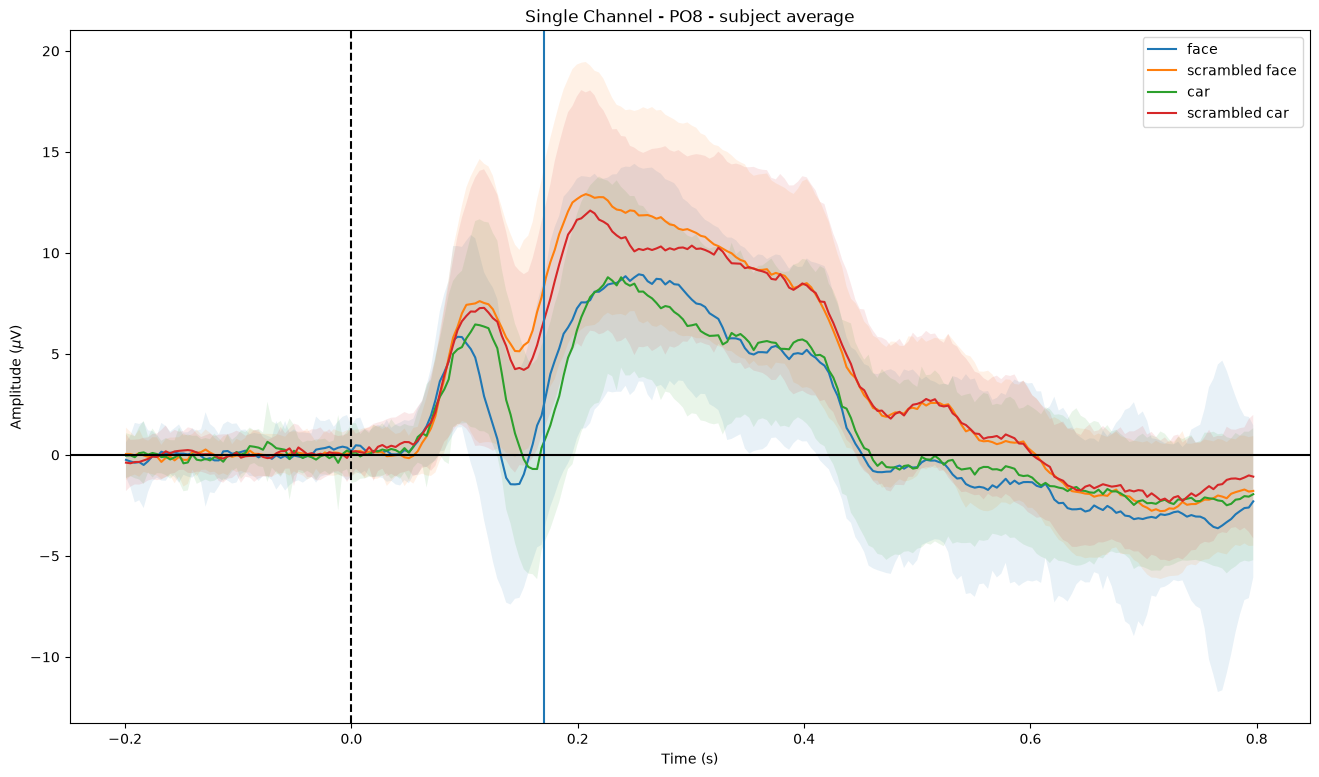

In [25]:
ax.set_title('Single Channel - '+ch_names[ch_idx]+' - subject average')

target_channel = 'PO8'
ch_idx = np.where(np.array(ch_names)==target_channel)[0][0]

all_subj_erp = all_subj_values[:,:,ch_idx]
fig, ax = plt.subplots(1, figsize=(16,9))
for c,condition in enumerate(conditions):
    ax.plot(times, all_subj_erp[:,c].mean(axis=0), label=condition)
    ax.fill_between(times,
                    all_subj_erp[:,c].mean(axis=0) - all_subj_erp[:,c].std(axis=0),
                    all_subj_erp[:,c].mean(axis=0) + all_subj_erp[:,c].std(axis=0), alpha=0.1)
plt.legend()
ax.axvline(0.170)
ax.axvline(0, linestyle='--',color='black')
ax.axhline(0,color='black')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude ($\mu$V)');
ax.set_title('Single Channel - '+ch_names[ch_idx]+' - subject average')


### Let's try to baseline correct the data

In [ ]:
# Time window in seconds: 160–180 ms
path='../content/'

exclude = [
    'HEOG_left',
    'HEOG_right',
    'VEOG_lower',
    '(corr) HEOG',
    '(corr) VEOG',
    '(uncorr) HEOG',
    '(uncorr) VEOG',
]

conditions = ['face', 'scrambled face', 'car', 'scrambled car']
baseline_mask = (times<=0) & (times>=-0.05) 

all_subj_values = []
for subj in range(1,41):# Loop over subjects    
    # path='../datasets/pfde9-osfstorage-N170 All Data and Scripts-archive/'+str(subj)+'/'
    # file_name=str(subj)+'_N170_shifted_ds_reref_ucbip_hpfilt_ica_corr_cbip_elist_bins_epoch.set'
    file_name = 'subj_'+subj+'.set'
    epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
    events = epochs.events # events id and correspondig time 
    events_id = epochs.event_id
    id_to_label = {v: k for k, v in events_id.items()}
    cond_by_trial = [id_to_label[event][:2] for event in events[:,-1] if id_to_label[event][0]=='B']# Assign to each trial the corresponding condition

    ch_names = epochs.ch_names
    times = epochs.times      

    # First calculate the values for every condition
    all_values = []
    condition_length = []
    for condition in conditions:
        trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
        # If there's an empty condition, skip the trial
        condition_length.append(len(trials_idx))
    if 0 in condition_length:
        continue
    else:
        for condition in conditions:
            trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
            epochs_plot = epochs[trials_idx].copy().pick("eeg")
            # Drop excluded channels
            epochs_plot.drop_channels([ch for ch in exclude if ch in epochs_plot.ch_names])
            epochs_plot_np = epochs_plot.get_data() # Convert to numpy array. Shape: (n_trial, c_channels, time)
            baseline_mean = epochs_plot_np[:,:,baseline_mask].mean(axis=-1, keepdims=True) # Extract the baseline mean from -0.100 to 0 with respect to the simulus onset
            baseline_std = epochs_plot_np[:,:,baseline_mask].std(axis=-1, keepdims=True) # Extract the baseline mean from -0.100 to 0 with respect to the simulus onset
            evoked = (epochs_plot_np-baseline_mean)/baseline_std # Z-scoring
            evoked = evoked.mean(axis=0) # Mean over trials
            all_values.append(evoked)
    all_values = np.stack(all_values)
    all_subj_values.append(all_values)
all_subj_values = np.stack(all_subj_values)
print(all_subj_values.shape)


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\3469684716.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\3469684716.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\3469684716.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\3469684716.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
C:\Users\alebo\AppData\Local\Tem

(40, 4, 28, 256)


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\3469684716.py:20: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Text(0.5, 1.0, 'Single Channel - PO8 - subject average')

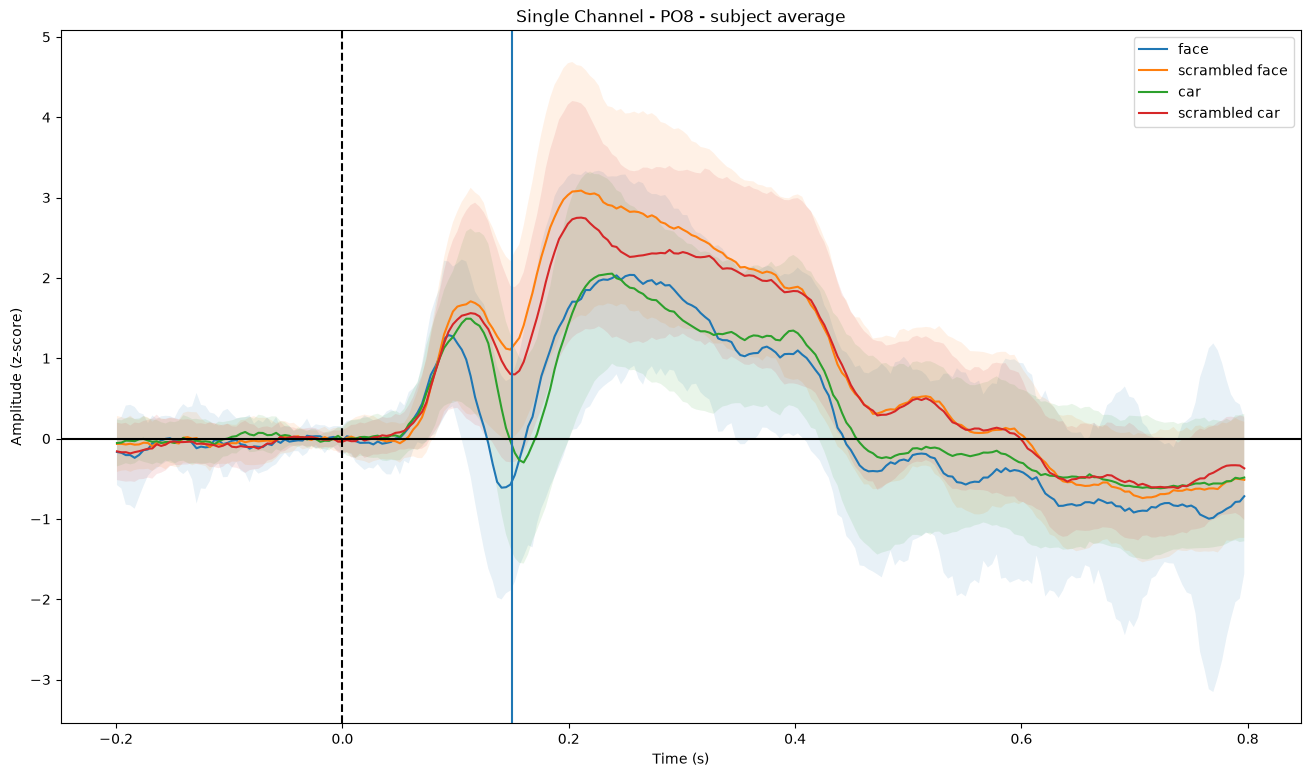

In [32]:
ax.set_title('Single Channel - '+ch_names[ch_idx]+' - subject average (z-scored amplitude)')

target_channel = 'PO8'
ch_idx = np.where(np.array(ch_names)==target_channel)[0][0]

all_subj_erp = all_subj_values[:,:,ch_idx]
fig, ax = plt.subplots(1, figsize=(16,9))
for c,condition in enumerate(conditions):
    ax.plot(times, all_subj_erp[:,c].mean(axis=0), label=condition)
    ax.fill_between(times,
                    all_subj_erp[:,c].mean(axis=0) - all_subj_erp[:,c].std(axis=0),
                    all_subj_erp[:,c].mean(axis=0) + all_subj_erp[:,c].std(axis=0), alpha=0.1)
plt.legend()
ax.axvline(0.150)
ax.axvline(0, linestyle='--',color='black')
ax.axhline(0,color='black')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Amplitude (z-score)');
ax.set_title('Single Channel - '+ch_names[ch_idx]+' - subject average')



### Plot the activity in a time window over the scalp for all the conditions - many subjects

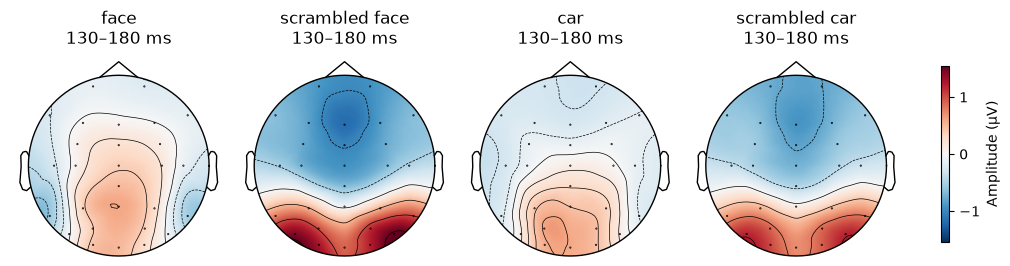

In [59]:
tmin, tmax = 0.130, 0.180
t_mask = (times>=tmin) & (times<=tmax)

# Common color limits, symmetric around zero
vmax = max(np.max(np.abs(all_subj_values[:,:,:,t_mask].mean(axis=-1).mean(axis=0))) for values in all_values)
if vmax == 0:
    vmax = 1.0

fig, axs = plt.subplots(1, len(conditions), figsize=(10, 4), constrained_layout=True)

for c, condition in enumerate(conditions):
    im, _ = mne.viz.plot_topomap(
        all_subj_values[:,:,:,t_mask].mean(axis=-1)[:,c].mean(axis=0),
        all_infos[c],
        axes=axs[c],
        cmap="RdBu_r",
        vlim=(-vmax, vmax),
        show=False,
    )

    axs[c].set_title(f"{condition:s}\n" f"{tmin * 1000:.0f}–{tmax * 1000:.0f} ms")

# One shared colorbar for all four maps
cbar = fig.colorbar(
    im,
    ax=axs.tolist(),
    orientation="vertical",
    shrink=0.45,
    fraction=0.035,
    pad=0.04,
)
cbar.set_label("Amplitude (µV)")

plt.show()

### Topographic map difference (with statistical test)

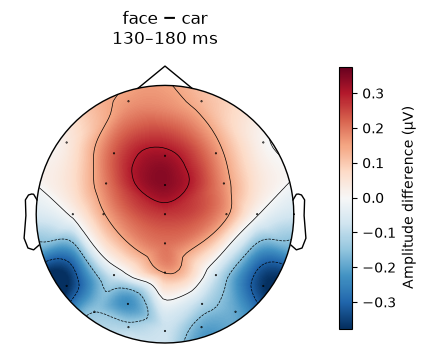

In [65]:
# Time window in seconds: 150–200 ms
tmin, tmax = 0.130, 0.180
t_mask = (times>=tmin) & (times<=tmax)

conditions = ['face', 'scrambled face', 'car', 'scrambled car']
target_conditions = ['face', 'car']


condition_values = []

# Difference between conditions
difference = all_subj_values[:,:,:,t_mask].mean(axis=-1)[:,0] - all_subj_values[:,:,:,t_mask].mean(axis=-1)[:,2] # Face - Car

fig, ax = plt.subplots(figsize=(5, 4))

# Symmetric color limits around zero
vmax = np.max(np.abs(difference.mean(axis=0)))
if vmax == 0:
    vmax = 1.0

im, _ = mne.viz.plot_topomap(
    difference.mean(axis=0),
    all_infos[0],
    axes=ax,
    cmap="RdBu_r",
    vlim=(-vmax, vmax),
    show=False,
)

fig.colorbar(im, ax=ax, label="Amplitude difference (µV)", shrink=0.85)
ax.set_title(
    f"{target_conditions[0]} − {target_conditions[1]}\n"
    f"{tmin * 1000:.0f}–{tmax * 1000:.0f} ms"
)
plt.show()

### Permutation cluster-test - many subject

Could not find a adjacency matrix for the data. Computing adjacency based on Delaunay triangulations.
-- number of adjacent vertices : 28
stat_fun(H1): min=1.784991717625021e-07 max=68.81984936971976
Running initial clustering …
Using 34 thresholds from 1.00 to 67.00 for TFCE computation (h_power=2.00, e_power=0.50)
Found 7168 clusters


100%|██████████| Permuting : 9999/9999 [00:34<00:00,  293.30it/s]


(28, 256)
[1. 1. 1. ... 1. 1. 1.]


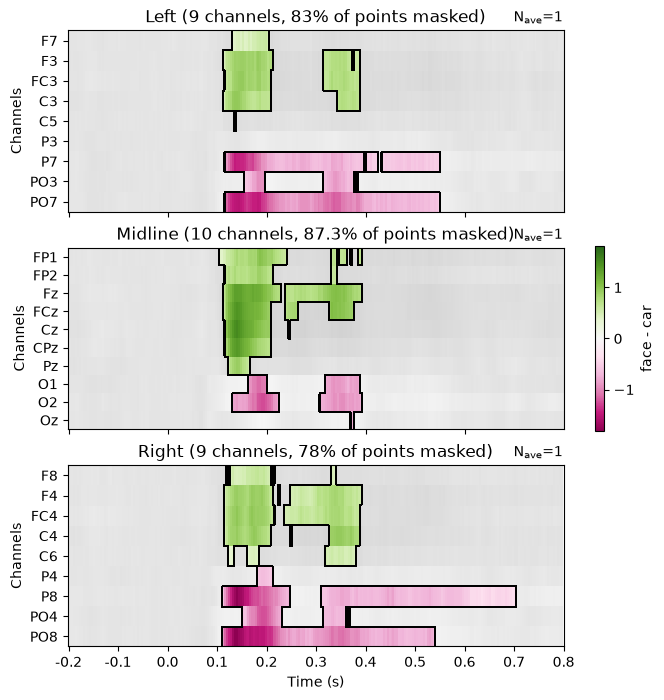

In [ ]:
### CLUSTER PERMUTATION T-TEST ###
conditions = ["face", "car"]
n_permutations = 10000
pv_threshold = 0.05

montage = epochs_exc_ch.get_montage()
info = mne.create_info(ch_names=montage.ch_names, sfreq=sfreq, ch_types='eeg')
info.set_montage(montage)
adjacency, ch = mne.channels.find_ch_adjacency(info, 'eeg')
tfce = dict(start=1, step=2) # threshold free cluster enhancement - ideally start and step would be smaller 

# Collect all trials belonging to each condition


a = all_subj_values[:,0]  # (n_subj, n_channels, n_times)
b = all_subj_values[:,1]  # (n_subj, n_channels, n_times)

difference = a - b

t_obs, clusters, cluster_pv, h0 = permutation_cluster_test([a.transpose(0,2,1), b.transpose(0,2,1)], 
                                                            threshold=tfce,
                                                            n_permutations=n_permutations, tail=0, 
                                                            n_jobs=-1, adjacency=adjacency)
                                                            # stat_fun=wilcoxon_stat_fun)
                                                            

# transpose clusters
clusters_=[]
for c in clusters:
    clusters_.append(c[::-1])
# Initialize a boolean mask for significant clusters (same shape as T_obs)
significant_points = np.zeros(t_obs.T.shape, dtype=bool)
# Mark cluster areas with p < 0.05 as significant
p_count=0
for cluster, p_val in zip(clusters_, cluster_pv):
    if p_val <= pv_threshold:
        significant_points[cluster] = True
        p_count +=1

print(significant_points.shape)
new_mask_diff = significant_points

# Create ROIs by checking channel labels
selections = make_1020_channel_selections(epochs_exc_ch.info, midline="12z")
time_unit = dict(time_unit="s")

# Visualize the results
diff = a.mean(axis=0) - b.mean(axis=0)
evoked_array = mne.EvokedArray(data=diff, info=info) # size: n_ch x time
fig, axes = plt.subplots(nrows=3, figsize=(8, 8))
axes = {sel: ax for sel, ax in zip(selections, axes.ravel())}
evoked_array.plot_image(
    axes=axes,
    group_by=selections,
    colorbar=False,
    show=False,
    cmap='PiYG',
    mask=new_mask_diff,
    # clim=dict(eeg=[-vmax, vmax]),
    show_names="all",
    titles=None,
    **time_unit,
    scalings = dict(eeg=1)
)

axes['Right'].set_xticks([x/10 for x in range(11)])
axes['Right'].set_xticklabels([round(x/10-0.2,2) for x in range(11)])

plt.colorbar(axes["Left"].images[-1], ax=list(axes.values()), shrink=0.3, label=conditions[0]+" - "+conditions[1]+' (z-score)')
print(cluster_pv)

# Frequency analysis

### Compute power spectral density

A power spectral density (PSD) describes how the mean squared amplitude of your EEG signal is distributed across frequencies. MNE’s compute_psd() estimates this using either Welch’s method or the multitaper method. Here we will use the Welch method, which consist in computing PSD through the fast fourier transoform algorithm for multiple segment of the original time series, and then avereging the PSD of the segment to obtain the PSD of the whole time series

In [ ]:
### The method compute_psd implemented by this cell use the whelch methods to compute psd. 
### Welch’s method [1] computes an estimate of the power spectral density by dividing the data into
### overlapping segments, computing a modified periodogram for each segment and averaging the periodogram.
path='../content/'
conditions = ['face', 'scrambled face', 'car', 'scrambled car']
channel = 'PO8'
exclude = [ 'HEOG_left',
            'HEOG_right',
            'VEOG_lower',
            '(corr) HEOG',
            '(corr) VEOG',
            '(uncorr) HEOG',
            '(uncorr) VEOG']  # Channels to exclude

# Use the full epoch; change these to select a time window
tmin, tmax = 0, epochs.times[-1]
fmin, fmax = 1, 100  # Hz

psd_average = {}
for condition in conditions:
    psd_average[condition] = []

for subj in range(1,41):# Loop over subjects

    print(f'Subject: {subj}')
    # path='../datasets/pfde9-osfstorage-N170 All Data and Scripts-archive/'+str(subj)+'/'
    # file_name=str(subj)+'_N170_shifted_ds_reref_ucbip_hpfilt_ica_corr_cbip_elist_bins_epoch.set'
    file_name = 'subj_'+subj+'.set'


    epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
    events = epochs.events # events id and correspondig time 
    events_id = epochs.event_id
    id_to_label = {v: k for k, v in events_id.items()}
    cond_by_trial = [id_to_label[event][:2] for event in events[:,-1] if id_to_label[event][0]=='B']# Assign to each trial the corresponding condition

    ch_names = epochs.ch_names
    times = epochs.times      

    # First calculate the values for every condition
    all_values = []
    condition_length = []
    for condition in conditions:
        trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
        # If there's an empty condition, skip the trial
        condition_length.append(len(trials_idx))
    if 0 in condition_length:
        continue
    else:
        for condition in conditions:
            trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])

            epochs_psd = epochs[trials_idx].copy().pick("eeg")
            epochs_psd.drop_channels([ch for ch in exclude if ch in epochs_psd.ch_names])
            epochs_psd.crop(tmin=tmin, tmax=tmax)

            # Welch PSD for each trial and channel
            # nperseg: Length of each segment. Defaults to None, but if window is str or tuple, is set to 256, and if window is array_like, is set to the length of the window.
            # nfft: is the number of points used for the FFT of each segment in Welch’s method. It controls the spacing of the returned frequency bins
            nperseg = min(int(round(epochs_psd.info["sfreq"])), len(epochs_psd.times),)

            ### mne methods to compute psd ###
            spectrum = epochs_psd.compute_psd(
                                                method="welch",
                                                fmin=fmin,
                                                fmax=fmax,
                                                n_fft=nperseg,
                                                n_per_seg=nperseg,
                                                n_overlap=nperseg // 2,
                                                average="mean",  # Average Welch segments within each trial
                                                verbose=False,
                                                )

            psds, freqs = spectrum.get_data(return_freqs=True)

            # Convert V²/Hz → µV²/Hz
            psds = psds * 1e12

            # Store individual spectra and their average across trials
            psd_average[condition].append(psds.mean(axis=0))

Subject: 1


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\2384685410.py:29: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Subject: 2


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\2384685410.py:29: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Subject: 3


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\2384685410.py:29: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


... (70 outputs left out)

Subject: 39


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\2384685410.py:29: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


Subject: 40


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\2384685410.py:29: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)


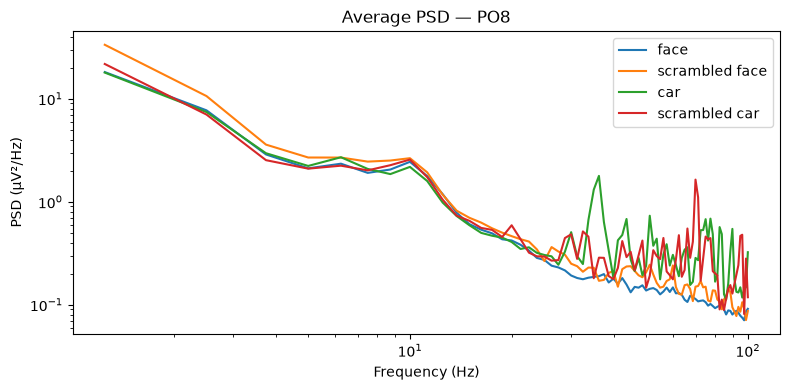

In [78]:
#----------
# Plot
#----------
channel='PO8'
fig, ax = plt.subplots(1, figsize=(8,4))
ch_idx = np.where(np.array(ch_names)==channel)[0][0]
for condition in conditions:
    ax.loglog(
        freqs,
        np.stack(psd_average[condition]).mean(axis=0)[ch_idx],
        label=condition,
    )

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (µV²/Hz)")
ax.set_title(f"Average PSD — {channel}")
ax.legend()
plt.tight_layout()
plt.show()

# Spectral exponent
Colombo et al. (2018). The spectral exponent of the resting EEG indexes the presence of consciousness during unresponsiveness induced by propofol, xenon, and ketamine. 
https://www.sciencedirect.com/science/article/pii/S1053811919300242?via%3Dihub

The **spectral exponent describes how rapidly power decreases as frequency increases**. In EEG, it usually refers to the exponent of the *aperiodic background* of the power spectral density (PSD).

Start with a power-law model:

$$
\boxed{P(f)=\frac{A}{f^\alpha}=A f^{-\alpha}}
$$

Here, $P(f)$ is the power spectral density at frequency $f$, $A>0$ sets the overall power scale, and $\alpha$ is the **spectral exponent**.

For example, doubling the frequency changes power by:

$$
\frac{P(2f)}{P(f)}
=
\frac{A(2f)^{-\alpha}}{Af^{-\alpha}}
=
2^{-\alpha}.
$$

Thus, a larger exponent means **less high-frequency power relative to low-frequency power**. It does not necessarily mean lower total power, because the scale $A$ can also differ.

Taking logarithms makes the relationship linear:

$$
\log P(f)=\log A-\alpha\log f.
$$

If we define $x=\log f$, $y=\log P(f)$, and $b=\log A$, this becomes:

$$
y=b-\alpha x.
$$

Therefore, on a plot with **both axes logarithmic**:

$$
\boxed{\text{slope}=-\alpha}.
$$

(36, 103)


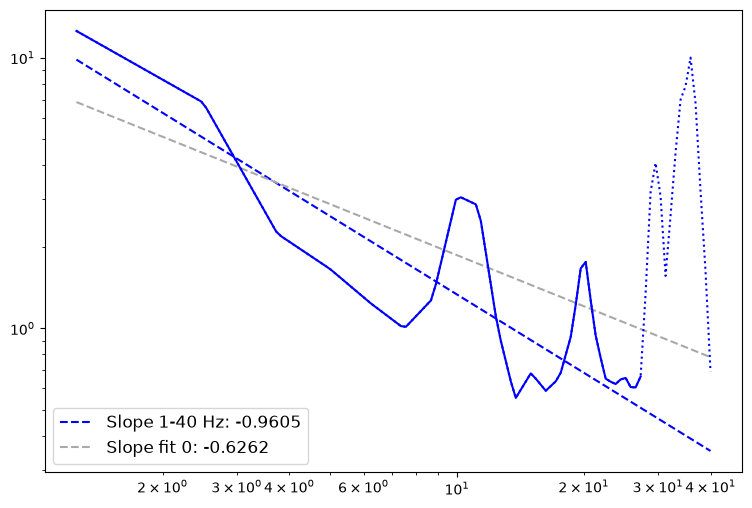

In [ ]:
### Compute psd using welch scipy methods ###
### In this methods the maximum frequency is defined by the Nyquist frequency: f_max=sfreq/2
### while the frequency bin spacing is defined by delta_f=sfreq/nfft

exclude = [ 'HEOG_left',
            'HEOG_right',
            'VEOG_lower',
            '(corr) HEOG',
            '(corr) VEOG',
            '(uncorr) HEOG',
            '(uncorr) VEOG']  # Channels to exclude

## psd parameters
sfreq=256 # Sampling frequency

condition = 'B2'
channel = 'O2'
ch_idx = np.where(np.array(ch_names)==channel)[0][0]
# Use the full epoch; change these to select a time window
tmin, tmax = 0, epochs.times[-1]
fmin, fmax = 1, 40  # Hz

trials_idx = np.array([event_id_dict[key] for key in event_id_dict if key[:2] == condition])

epochs_psd = epochs[trials_idx].copy().pick("eeg")
epochs_psd.drop_channels([ch for ch in exclude if ch in epochs_psd.ch_names])
epochs_psd.crop(tmin=tmin, tmax=tmax)
ch_idx = epochs_psd.ch_names.index(channel)
ts = epochs_psd.get_data()[:,ch_idx,:]

nperseg=min(int(round(epochs_psd.info["sfreq"])), len(epochs_psd.times),) 
noverlap=nperseg // 2

frex, psd = welch(ts, 
                  fs=sfreq, 
                  nperseg=nperseg, 
                  noverlap=noverlap, 
                  detrend='constant', 
                  nfft=nperseg,
                  window="hamming", # Explanation below
                  scaling="density",
                  average="mean",
                  )

################################################################################################################################
### "hamming" is the window applied to each segment before computing its FFT.                                                ###
### It weights the samples: those near the centre keep almost their full amplitude, while those near the edges are reduced.  ###
### Why do this? Cutting a signal into segments can create abrupt boundaries.                                                ###
### These boundaries cause spectral leakage: power from one frequency spreads into neighbouring frequencies.                 ###
### A Hamming window reduces this effect.                                                                                    ###
################################################################################################################################

# Convert V²/Hz → µV²/Hz
psd = psd * 1e12

print(psd.shape)

# Bound the welch output to our target frequency range
frBins = np.arange(dsearchn(frex, fmin), dsearchn(frex, fmax)+1)
XX = frex[frBins]
# spectral exponent
YY = psd.mean(axis=0)[frBins] ### TRIAL AVERAGE. To compute the spectral exponent for the trial average is different to compoute it for every single trial and then everaging the resulting exponents...
# YY = psd[0][frBins] 

X = np.log10(XX)
Y = np.log10(YY)

# UPSAMPLE AND INTERPOLATE IN LOG-LOG:  X, Y --> Xi, Yi
XXi = np.logspace(X[0], X[-1],len(X)*4)
Xi = np.log10(XXi) # x=logf
Yi = np.interp(Xi, X, Y,) # y=logP(f)
YYi = 10**(Yi)

# STEP 1, FIT 1st LINE
linfit0 = linregress(Xi, Yi) # alternative = 'less'???
slope0, intercept0 = linfit0[0], linfit0[1]
YPred0 = Xi*slope0+intercept0 # Linear interpolation
YRes0 = Yi-YPred0 # Residuals, difference between the linear interpolation and the actual psd
sigma0 = np.sqrt(np.mean(YRes0**2)) 

# FIND DEVIANT RESIDUALS (from the linear interpolation)
threRes = 0
boolYdev = YRes0 > threRes
idxs_dev = np.argwhere(np.diff(boolYdev,  prepend=False, append=False)).reshape(-1,2)

# Find peaks to be excluded next
idxs_peaks = find_peaks(Yi)[0]
threResPks= np.median(np.absolute(YRes0 - np.median(YRes0)))*1 # Median residuals
    
#     threResPks= max(threResPks, .1) # this is a heuristc value based on typical psd from eeg with unit of microV^2/Hz

idxs_peaks = idxs_peaks[YRes0[idxs_peaks] > threResPks]
boolYdev2 = np.zeros_like(boolYdev)
for idx_start, idx_end in idxs_dev:
    range_dev = np.arange(idx_start, idx_end)
    # where there are peaks with large residuals, set 1 in the boolean used for subsequent exclusion of peaks
    boolYdev2[range_dev] = np.any(np.intersect1d(idxs_peaks, range_dev)) 
    
# STEP 2 , FIT 2nd line after excluding peaks
linfit = linregress(Xi[~boolYdev2], Yi[~boolYdev2])
slope, intercept = linfit[0], linfit[1]
YPred = Xi*slope+intercept
YRes = Yi[~boolYdev2]-YPred[~boolYdev2]
sigma = np.sqrt(np.mean(YRes**2))

# PLOT FINAL SLOPE
fig, ax = plt.subplots(1, figsize=(9,6))
YYpred = 10**(slope*Xi+intercept)
lab = f'Slope {int(np.round(XX)[0])}-{int(np.round(XX)[-1])} Hz: {np.round(slope,4)}'
ax.plot(XXi, YYpred, '--', c='b', label=lab)

# PLOT SLOPE FIT0
YYpred0 = 10**(slope0*Xi+intercept0)
lab0 = f'Slope fit 0: {np.round(slope0,4)}'
ax.plot(XXi, YYpred0, '--', c='darkgrey', label=lab0)

# PLOT PSD
ax.plot(XXi, YYi, ':', c='b')
xPlot= XXi.copy(); xPlot[boolYdev2] = np.nan
ax.plot(xPlot, 10.**(Yi), '-', c='b')

ax.loglog()
# ax.xticks(np.round(XXi[::20],1), rotation=45)
ax.legend(fontsize=12)

We could compute the spectral exponent for each channel and make a comparison between conditions...

# Time-frequency analysis - many subjects
Here we apply morlet-wavelets decomposition to obtain a spectral decomposition in time. Morlet time–frequency analysis estimates how strongly different frequencies are present at each moment in EEG data. Morlet analysis gives a frequency × time map, so you can see, for example, whether alpha power decreases after stimulus onset.

A Morlet wavelet is a short oscillation whose amplitude gradually increases and decreases according to a Gaussian envelope:

$$
\underbrace{\psi_f(t)}_{\text{wavelet}}
\propto
\underbrace{e^{i2\pi ft}}_{\text{oscillation at frequency }f}
\underbrace{e^{-t^2/(2\sigma_t^2)}}_{\text{Gaussian envelope}}
$$

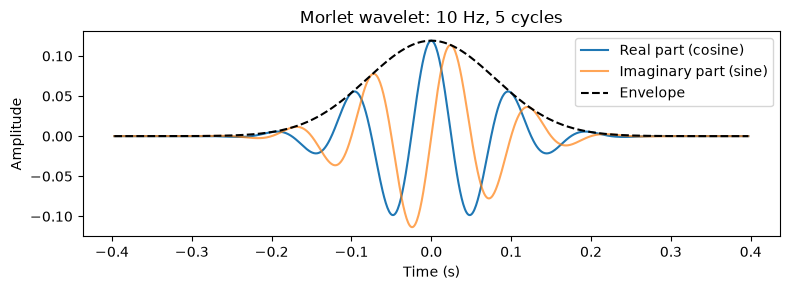

In [ ]:
#------------------------
# Morlet wavalets example
#------------------------


sfreq = 1000  # Sampling frequency, Hz
freq = 10    # Wavelet frequency, Hz
n_cycles = 5

wavelet = morlet(
    sfreq=sfreq,
    freqs=[freq],
    n_cycles=n_cycles,
    zero_mean=True,
)[0]

times = (np.arange(len(wavelet)) - len(wavelet) // 2) / sfreq

plt.figure(figsize=(8, 3))
plt.plot(times, wavelet.real, label="Real part (cosine)")
plt.plot(times, wavelet.imag, label="Imaginary part (sine)", alpha=0.7)
plt.plot(times, np.abs(wavelet), "k--", label="Envelope")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Morlet wavelet: {freq} Hz, {n_cycles} cycles")
plt.legend()
plt.tight_layout()
plt.show()

Imagine sliding a small 10-Hz oscillation along your EEG:
- Where the EEG contains a strong 10-Hz component, the wavelet response is large.
- Where that component is weak, the response is small.
- Repeat with wavelets at every frequency in freqs.

This sliding operation is called convolution. For trial $r$, it produces a complex coefficient $Z_r(f,t)$.

Its squared magnitude gives power:
$$
P_r(f,t)=|Z_r(f,t)|^2
=
\operatorname{Re}(Z_r)^2+\operatorname{Im}(Z_r)^2.
$$

Considering a discrete eeg time series x, the convolution result che be expressed as:

$$
Z_f[n]=\sum_k x[k]\,\psi_f[n-k]
$$

In [ ]:
#----------------------------------
# Compute time frequency spectrum
#----------------------------------
path='../content/'

n_cycles = 4
freqs= np.arange(8,50,1)

exclude = [
    'HEOG_left',
    'HEOG_right',
    'VEOG_lower',
    '(corr) HEOG',
    '(corr) VEOG',
    '(uncorr) HEOG',
    '(uncorr) VEOG',
]

conditions = ['face', 'scrambled face', 'car', 'scrambled car']

powers_all_subj = []
for subj in range(1,41):# Loop over subjects    
    print(f'Subject: {subj}')
    # path='../datasets/pfde9-osfstorage-N170 All Data and Scripts-archive/'+str(subj)+'/'
    # file_name=str(subj)+'_N170_shifted_ds_reref_ucbip_hpfilt_ica_corr_cbip_elist_bins_epoch.set'
    file_name='subj_'+subj+'.set'

    epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
    events = epochs.events # events id and correspondig time 
    events_id = epochs.event_id
    id_to_label = {v: k for k, v in events_id.items()}
    cond_by_trial = [id_to_label[event][:2] for event in events[:,-1] if id_to_label[event][0]=='B']# Assign to each trial the corresponding condition

    ch_names = epochs.ch_names
    times = epochs.times      

    # First calculate the values for every condition
    all_values = []
    condition_length = []
    for condition in conditions:
        trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
        # If there's an empty condition, skip the trial
        condition_length.append(len(trials_idx))
    if 0 in condition_length:
        continue
    else:
        for condition in conditions:
            trials_idx = np.array([e for e,trial_cond in enumerate(cond_by_trial) if condition_dict[trial_cond]==condition])
            epochs_plot = epochs[trials_idx].copy().pick("eeg")
            # Drop excluded channels
            epochs_plot.drop_channels([ch for ch in exclude if ch in epochs_plot.ch_names])
            info = epochs_plot.info
            evoked = epochs_plot.get_data() # Mean over trials
            # Average across time and convert to µV
            all_values.append(evoked)



    powers_all_cond = []
    for c,condition in enumerate(conditions):
        trialz = all_values[c]
        print(trialz.shape)
        epochs = mne.EpochsArray(trialz, info)  

        # Compute the time-frequency representation using Morlet wavelets
        # power = mne.time_frequency.tfr_morlet()
        power = mne.time_frequency.tfr_morlet(epochs,
                                              freqs=freqs,
                                              n_cycles=n_cycles,
                                              return_itc=False,
                                              decim=3,
                                              n_jobs=-1,
                                              average=True)
        power.apply_baseline(baseline=(0.1, 0.2), mode='percent')
        power.crop(tmin=0.2, tmax=times.max())
        print(power.data.shape)
        power_times = power.times - power.times[0]

        powers_all_cond.append(power.data)
    powers_all_cond = np.stack(powers_all_cond)
    print(powers_all_cond.shape)
    powers_all_subj.append(powers_all_cond)
powers_all_subj = np.stack(powers_all_subj)
print(powers_all_subj.shape)

Subject: 1
(61, 28, 256)
Not setting metadata
61 matching events found
No baseline correction applied
0 projection items activated
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").


C:\Users\alebo\AppData\Local\Temp\ipykernel_23908\4107388247.py:24: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(path+file_name, verbose=0)
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    8.1s


Applying baseline correction (mode: percent)
(28, 42, 52)
(65, 28, 256)
Not setting metadata
65 matching events found
No baseline correction applied
0 projection items activated
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").


[Parallel(n_jobs=-1)]: Done  28 out of  28 | elapsed:    8.7s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.5s


Applying baseline correction (mode: percent)
(28, 42, 52)
(53, 28, 256)
Not setting metadata
53 matching events found
No baseline correction applied
0 projection items activated
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").


[Parallel(n_jobs=-1)]: Done  28 out of  28 | elapsed:    1.5s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.9s


... (428 outputs left out)

Applying baseline correction (mode: percent)
(28, 42, 52)
(76, 28, 256)
Not setting metadata
76 matching events found
No baseline correction applied
0 projection items activated
NOTE: tfr_morlet() is a legacy function. New code should use .compute_tfr(method="morlet").


[Parallel(n_jobs=-1)]: Done  28 out of  28 | elapsed:    1.0s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.5s


Applying baseline correction (mode: percent)
(28, 42, 52)
(4, 28, 42, 52)
(40, 4, 28, 42, 52)


[Parallel(n_jobs=-1)]: Done  28 out of  28 | elapsed:    1.0s finished


stat_fun(H1): min=-3.7491019574867708 max=4.943617023930757
Running initial clustering …
Using 49 thresholds from 0.10 to 4.90 for TFCE computation (h_power=2.00, e_power=0.50)
Found 2184 clusters


100%|██████████| Permuting : 99/99 [00:00<00:00,  122.06it/s]


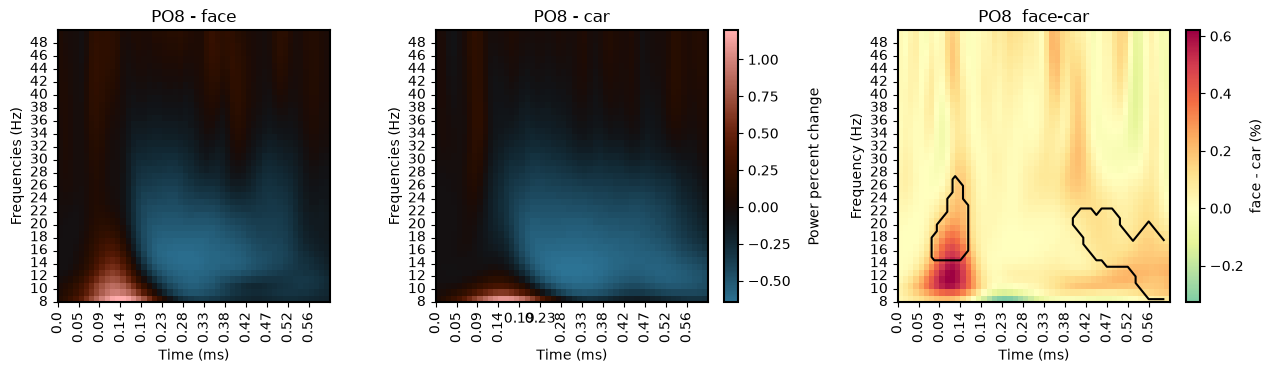

In [144]:
conditions = ['face','car']
conditions_idx = [0,2]
channel = 'PO8'
ch_idx = np.where(np.array(ch_names)==channel)[0][0]

n_permutations=100
heatmap_positions = [
    [0.06, 0.20, 0.25, 0.68],  # first heatmap
    [0.37, 0.20, 0.25, 0.68],  # second heatmap
    [0.68, 0.20, 0.25, 0.68],  # difference heatmap
]

colorbar_positions = {
    1: [0.63, 0.20, 0.015, 0.68],  # second heatmap's colorbar
    2: [0.94, 0.20, 0.015, 0.68],  # difference heatmap's colorbar
}

times = power_times
tfce = dict(start=0.1, step=0.1) # ideally start and step would be smaller
data_diff = []
fig, axs = plt.subplots(1, 3, figsize=(14,4))
data = []
data_avg = []
vmin = 1
vmax = 0
for c, condition in enumerate(conditions):
    powers = powers_all_subj[:,conditions_idx[c],ch_idx]
    avg_powers = np.stack(powers, axis=0).mean(axis=0)
    vmin_ = avg_powers.min()
    vmax_ = avg_powers.max()
    if vmin_<vmin:
        vmin = vmin_ 
    if vmax_>vmax:
        vmax = vmax_ 
for c, condition in enumerate(conditions):
    powers = powers_all_subj[:,conditions_idx[c],ch_idx]
    avg_powers = np.stack(powers, axis=0).mean(axis=0)
    # print(np.stack(powers,axis=0).shape, avg_powers.shape)
    data.append(np.stack(powers,axis=0))
    data_avg.append(avg_powers)
    if c==0:
        cbar_ = False
    else:
        cbar_ = True
    cmap = 'berlin'
    sns.heatmap(avg_powers, cmap=cmap, ax=axs[c],
                vmin=vmin,vmax=vmax, center=0, cbar=cbar_,
                xticklabels=[round(t,3) for i,t in enumerate(times) if i%15==0])
    axs[c].invert_yaxis()
    axs[c].set_title(f'{channel} - {condition}', fontsize=12)
    axs[c].set_xlabel('Time (ms)')
    axs[c].set_ylabel('Frequencies (Hz)')

    ## x ticks labels ##
    axs[c].set_xticks(np.arange(0,len(power_times),4))
    axs[c].set_xticklabels([np.round(t,2) for i,t in enumerate(power_times) if i%4==0])
    
    # y ticks labels ##
    axs[c].set_yticks(np.arange(0,len(freqs),2));
    axs[c].set_yticklabels([f for f in freqs if f%2==0], rotation=0);  # Rotate labels if needed
    # Get the list of tick objects and their corresponding text labels
    ticks = axs[c].yaxis.get_major_ticks()
    labels = axs[c].get_yticklabels()


    for spine in axs[c].spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.5)

    if cbar_:
        # Access the colorbar (the first collection is used by the heatmap)
        cbar = axs[c].collections[0].colorbar
        # Set a border on the colorbar by adjusting its outline properties
        cbar.outline.set_linewidth(1.5)       # Set border thickness
        cbar.outline.set_edgecolor('black')  # Set border color
        
        cbar.set_label("Power percent change", labelpad=12)
    
data_diff.append(data[0]-data[1])
#### PLOT THE DIFFERENCE BETWEEN FACE AND CONTROL TRIALS
### CLUSTER PERMUTATION TEST ###
T_obs, clusters, cluster_p_values, H0 = permutation_cluster_1samp_test(data[0]-data[1],
                                                                        n_permutations=n_permutations, 
                                                                        threshold=tfce,
                                                                        tail=0, 
                                                                        n_jobs=-1)


sig_mask = np.zeros(T_obs.shape, dtype=bool)

# Mark cluster areas with p < 0.05 as significant
for cluster, p_val in zip(clusters, cluster_p_values):
    if p_val < 0.05:
        sig_mask[cluster] = True
# --- Plotting with Seaborn and Overlaying Clusters ---
# Create a seaborn heatmap of the test statistic (T_obs)

sns.heatmap(data_avg[0]-data_avg[1], ax=axs[-1], cmap='Spectral_r', cbar=True,center=0,
            xticklabels=10, yticklabels=5)  # adjust tick parameters as needed
# Overlay significant clusters as contours.
# Here we use a contour at the 0.5 level of the boolean mask (converting it to float)
cs = axs[-1].contour(sig_mask.astype(float), levels=[0.5], colors='black', linewidths=1.5)

# Optionally, add a title or axis labels
axs[-1].set_title(f'{channel}  {conditions[0]}-{conditions[1]}', fontsize=12)
axs[-1].set_xlabel('Time (ms)')
axs[-1].set_ylabel('Frequency (Hz)')
axs[-1].invert_yaxis()

## x ticks labels ##
axs[-1].set_xticks(np.arange(0,len(power_times),4))
axs[-1].set_xticklabels([np.round(t,2) for i,t in enumerate(power_times) if i%4==0], rotation=90)

# y ticks labels ##
axs[-1].set_yticks(np.arange(0,len(freqs),2));
axs[-1].set_yticklabels([f for f in freqs if f%2==0], rotation=0);  # Rotate labels if needed


for spine in axs[-1].spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(1.5)
# Access the colorbar (the first collection is used by the heatmap)
cbar = axs[-1].collections[0].colorbar

# Set a border on the colorbar by adjusting its outline properties
cbar.outline.set_linewidth(1.5)       # Set border thickness
cbar.outline.set_edgecolor('black')  # Set border color

cbar.set_label(f"{conditions[0]} - {conditions[1]} (%)", labelpad=4)

# Difference between face and control trials
plt.tight_layout()



### Set boxes size ###
fig_w, fig_h = fig.get_size_inches()

box_h = 0.68
box_w = box_h * fig_h / fig_w  # makes width and height equal in inches
bottom = (1 - box_h) / 2
lefts = [0.05, 0.32, 0.65]

cbar_gap = 0.012
cbar_width = 0.015

for i, ax in enumerate(axs):
    ax.set_position([lefts[i], bottom, box_w, box_h])
    ax.set_aspect("auto")

    if i in (1, 2):
        cbar = ax.collections[0].colorbar
        cbar.ax.set_position([
            lefts[i] + box_w + cbar_gap,
            bottom,
            cbar_width,
            box_h,
        ])